# Insect Photo Dataset — Data Audit & Analysis

**Source:** [iNaturalist API](https://api.inaturalist.org/v1/observations) — research-grade
observations of *Insecta* from Cyprus (`place_id=10289`), openly licensed photos only.
Collected by `Data/retriever.py`.

**Intended downstream use:** a supervised image classifier that maps an insect photo to a taxon.
Every check below is therefore framed by one question: *can this table be turned into a
trustworthy train/validation/test split?*

## Contents

| § | Section | Question answered |
|---|---------|-------------------|
| 1 | Setup | — |
| 2 | Loading & first look | What is in the file? |
| 3 | Schema & type audit | Are the columns what they claim to be? |
| 4 | Missing values | What is absent, and does it matter? |
| 5 | Duplicates & record granularity | What is one row? Are rows independent? |
| 6 | Taxonomic label audit | Are the labels a consistent target variable? |
| 7 | Class distribution & imbalance | How usable are the classes? |
| 8 | Licence audit | What are we legally allowed to do? |
| 9 | Contributor audit | Who produced the data, and does that bias it? |
| 10 | Location audit | Where do the observations come from? |
| 11 | Photo URL audit | Are the images usable as model input? |
| 12 | Data-quality scorecard & cleaned export | — |
| 13 | Findings & recommendations | So what? |

---
## 1. Setup

A single fixed categorical palette is used throughout, in fixed order, so that a colour always
means the same thing across figures. Grid and axes are kept recessive so the data marks dominate.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 90)

# --- plot theme -------------------------------------------------------------
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
       "#e87ba4", "#008300", "#4a3aa7", "#e34948"]   # fixed categorical order
SEQ = "Blues"                                        # single-hue sequential ramp
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "axes.labelcolor": MUTED,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlecolor": INK,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "font.size": 9,
    "legend.frameon": False,
})

# format a count as 'n (p%)'
def pct(x, n):
    return f"{x:,} ({x / n:.1%})"

---
## 2. Loading & first look

The CSV is read with **no dtype coercion at all** — `observation_id` stays a string on the first
pass so that any non-numeric junk in the column shows up instead of being silently dropped by the
parser. Types are asserted deliberately in §3.

In [2]:
DATA = Path.cwd().parent / "Data" / "insects.csv"
if not DATA.exists():                     # fall back if the notebook is run from the repo root
    DATA = Path("Data/insects.csv")

raw = pd.read_csv(DATA, dtype=str, keep_default_na=False, na_values=[""])
print(f"file      : {DATA.resolve()}")
print(f"size      : {DATA.stat().st_size / 1e6:.1f} MB")
print(f"shape     : {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"columns   : {list(raw.columns)}")
raw.head()

file      : /Users/nicolasdilegardia/Desktop/insects/Data/insects.csv
size      : 4.1 MB
shape     : 21,403 rows x 6 columns
columns   : ['observation_id', 'taxon_name', 'photo_url', 'license_code', 'attribution', 'location']


,observation_id,taxon_name,photo_url,license_code,attribution,location
0,387625264,Utetheisa pulchella,https://inaturalist-open-data.s3.amazonaws.com/photos/709822987/square.jpg,cc-by-nc,"(c) Reflectitur Photons, some rights reserved (CC BY-NC)","Nicosia, Cyprus"
1,387625095,Macroscytus brunneus,https://inaturalist-open-data.s3.amazonaws.com/photos/709822622/square.jpg,cc-by-nc,"(c) Reflectitur Photons, some rights reserved (CC BY-NC)","Nicosia, Cyprus"
2,387625063,Vespa orientalis,https://inaturalist-open-data.s3.amazonaws.com/photos/709822553/square.jpg,cc-by-nc,"(c) Reflectitur Photons, some rights reserved (CC BY-NC)","Nicosia, Cyprus"
3,387618636,Phoracantha recurva,https://inaturalist-open-data.s3.amazonaws.com/photos/709810271/square.jpg,cc-by-nc,"(c) Reflectitur Photons, some rights reserved (CC BY-NC)","Nicosia, Cyprus"
4,387618636,Phoracantha recurva,https://inaturalist-open-data.s3.amazonaws.com/photos/709810366/square.jpg,cc-by-nc,"(c) Reflectitur Photons, some rights reserved (CC BY-NC)","Nicosia, Cyprus"


In [3]:
# A wide row printed vertically is easier to read than a truncated table.
raw.iloc[0].to_frame("first record")

,first record
observation_id,387625264
taxon_name,Utetheisa pulchella
photo_url,https://inaturalist-open-data.s3.amazonaws.com/photos/709822987/square.jpg
license_code,cc-by-nc
attribution,"(c) Reflectitur Photons, some rights reserved (CC BY-NC)"
location,"Nicosia, Cyprus"


### 3. Schema & type audit

What the columns are *supposed* to be, from the retriever code:

| column | source field | expected type | expected semantics |
|---|---|---|---|
| `observation_id` | `results[].id` | int | iNaturalist observation key — **not** unique per row |
| `taxon_name` | `results[].taxon.name` | str | scientific name at the observation's identified rank |
| `photo_url` | `photos[].url` | str (URL) | thumbnail image location |
| `license_code` | `photos[].license_code` | categorical | Creative Commons code |
| `attribution` | `photos[].attribution` | str | copyright line containing the photographer |
| `location` | `results[].place_guess` | str (free text) | user-typed place, uncontrolled |

Note the join: one *observation* fans out to one row **per photo**. That is the single most
important structural fact in the file, and §5 quantifies it.

In [4]:
def schema_report(df):
    rows = []
    for c in df.columns:
        s = df[c]
        rows.append({
            "column": c,
            "dtype": str(s.dtype),
            "non_null": s.notna().sum(),
            "missing": s.isna().sum(),
            "missing_%": round(s.isna().mean() * 100, 2),
            "unique": s.nunique(dropna=True),
            "unique_%": round(s.nunique(dropna=True) / len(s) * 100, 2),
            "example": s.dropna().iloc[0][:60] if s.notna().any() else None,
        })
    return pd.DataFrame(rows).set_index("column")

schema_report(raw)

,dtype,non_null,missing,missing_%,unique,unique_%,example
column,,,,,,,
observation_id,object,21403,0,0.00,12093,56.50,387625264
taxon_name,object,21403,0,0.00,1154,5.39,Utetheisa pulchella
photo_url,object,21403,0,0.00,21397,99.97,https://inaturalist-open-data.s3.amazonaws.com/photos/709822
license_code,object,21402,1,0.00,5,0.02,cc-by-nc
attribution,object,21403,0,0.00,791,3.70,"(c) Reflectitur Photons, some rights reserved (CC BY-NC)"
location,object,21095,308,1.44,2131,9.96,"Nicosia, Cyprus"


In [5]:
# Is observation_id really an integer everywhere?
bad_id = raw.loc[~raw["observation_id"].str.fullmatch(r"\d+", na=False), "observation_id"]
print(f"non-integer observation_id values : {len(bad_id)}")

# Is photo_url really a URL everywhere?
bad_url = raw.loc[~raw["photo_url"].str.match(r"^https?://", na=False), "photo_url"]
print(f"non-URL photo_url values          : {len(bad_url)}")

# Any stray whitespace that would break groupby / joins later?
for c in ["taxon_name", "license_code", "location"]:
    n = (raw[c].fillna("") != raw[c].fillna("").str.strip()).sum()
    print(f"untrimmed whitespace in {c:<13}: {n}")

non-integer observation_id values : 0
non-URL photo_url values          : 0
untrimmed whitespace in taxon_name   : 0
untrimmed whitespace in license_code : 0
untrimmed whitespace in location     : 19


In [6]:
# Types are safe to assert -> build the working frame.
df = raw.copy()
df["observation_id"] = df["observation_id"].astype("int64")
df["license_code"] = df["license_code"].astype("category")
df["taxon_name"] = df["taxon_name"].str.strip()
df.dtypes

observation_id       int64
taxon_name          object
photo_url           object
license_code      category
attribution         object
location            object
dtype: object

---
## 4. Missing values

Missingness is only a problem relative to what a column is *for*. `location` is metadata; a null
there costs an analysis, not a training example. A null `photo_url` or `taxon_name` would destroy
the example outright.

,missing,pct
location,308,1.44
license_code,1,0.00


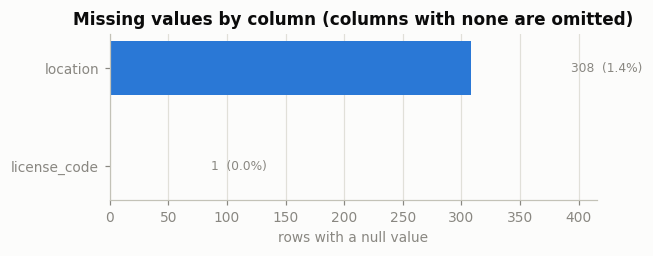

In [7]:
miss = df.isna().sum().sort_values(ascending=False)
miss = miss[miss > 0]
display(miss.to_frame("missing").assign(pct=lambda d: (d["missing"] / len(df) * 100).round(2)))

fig, ax = plt.subplots(figsize=(6, 2.4))
ax.barh(miss.index[::-1], miss.values[::-1], color=CAT[0], height=0.55)
for y, v in enumerate(miss.values[::-1]):
    ax.text(v + len(df) * 0.004, y, f"{v:,}  ({v/len(df):.1%})",
            va="center", fontsize=8, color=MUTED)
ax.set_xlim(0, miss.max() * 1.35)
ax.set_xlabel("rows with a null value")
ax.set_title("Missing values by column (columns with none are omitted)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [8]:
# The two label-critical columns must be complete.
assert df["taxon_name"].notna().all(), "missing labels!"
assert df["photo_url"].notna().all(), "missing images!"
print("taxon_name and photo_url are 100% complete -- every row is a usable (image, label) pair.")

# Who is missing a location, and is it concentrated in a few observations?
no_loc = df[df["location"].isna()]
print(f"\nrows without location  : {pct(len(no_loc), len(df))}")
print(f"distinct observations  : {no_loc['observation_id'].nunique():,} "
      f"of {df['observation_id'].nunique():,}")
print(f"distinct contributors  : {no_loc['attribution'].nunique():,}")

taxon_name and photo_url are 100% complete -- every row is a usable (image, label) pair.

rows without location  : 308 (1.4%)
distinct observations  : 160 of 12,093
distinct contributors  : 49


In [9]:
# The single null licence -- inspect it rather than impute it.
df[df["license_code"].isna()].T

,5791
observation_id,288831592
taxon_name,Pentodon algerinus dispar
photo_url,https://static.inaturalist.org/photos/519452246/square.jpg
license_code,NaN
attribution,"(c) Jan Vospálek, all rights reserved"
location,"Limassol, CY"


**Finding.** One photo carries `license_code = NaN` while its attribution reads *"all rights
reserved"*. The retriever requested only open licences, so this row is an API inconsistency: the
photo licence is absent even though the observation qualified. It is **not** missing-at-random and
must not be imputed — it is dropped in §12, because using an all-rights-reserved image would be a
licence violation, not a data-quality nuisance.

---
## 5. Duplicates & record granularity

Three different notions of "duplicate" apply here, and they have opposite implications:

1. **Exact duplicate rows** — pure noise, drop.
2. **Repeated `photo_url`** — the same image file under two observation ids; a hard leak if the
   copies land in different splits.
3. **Repeated `observation_id`** — *expected*, because the retriever emits one row per photo. Not
   an error, but it means rows are **not independent**: several photos of the same individual
   insect, same background, same minute.

In [10]:
print(f"exact duplicate rows        : {df.duplicated().sum():,}")
print(f"duplicated photo_url values : {df['photo_url'].duplicated().sum():,}")
print(f"duplicated observation_id   : {df['observation_id'].duplicated().sum():,}")
print(f"distinct observations       : {df['observation_id'].nunique():,}")
print(f"distinct photos             : {df['photo_url'].nunique():,}")

exact duplicate rows        : 0
duplicated photo_url values : 6
duplicated observation_id   : 9,310
distinct observations       : 12,093
distinct photos             : 21,397


In [11]:
# The repeated image files, in full.
dup_urls = df[df["photo_url"].duplicated(keep=False)].sort_values("photo_url")
dup_urls[["observation_id", "taxon_name", "photo_url", "attribution"]]

,observation_id,taxon_name,photo_url,attribution
19162,40886476,Cydnus aterrimus,https://inaturalist-open-data.s3.amazonaws.com/photos/51869419/square.jpg,"(c) Sandy Rae, some rights reserved (CC BY)"
20226,33045443,Cydnus aterrimus,https://inaturalist-open-data.s3.amazonaws.com/photos/51869419/square.jpg,"(c) Sandy Rae, some rights reserved (CC BY)"
19167,40886336,Deraeocoris rutilus,https://inaturalist-open-data.s3.amazonaws.com/photos/51869997/square.jpg,"(c) Sandy Rae, some rights reserved (CC BY)"
20217,33045791,Deraeocoris rutilus,https://inaturalist-open-data.s3.amazonaws.com/photos/51869997/square.jpg,"(c) Sandy Rae, some rights reserved (CC BY)"
86,383002681,Ischnura intermedia,https://inaturalist-open-data.s3.amazonaws.com/photos/700948773/square.jpg,"(c) Dr. Günther Fuchs, some rights reserved (CC BY-NC)"
89,383002680,Ischnura intermedia,https://inaturalist-open-data.s3.amazonaws.com/photos/700948773/square.jpg,"(c) Dr. Günther Fuchs, some rights reserved (CC BY-NC)"
84,383002691,Ischnura intermedia,https://inaturalist-open-data.s3.amazonaws.com/photos/700948797/square.jpg,"(c) Dr. Günther Fuchs, some rights reserved (CC BY-NC)"
87,383002681,Ischnura intermedia,https://inaturalist-open-data.s3.amazonaws.com/photos/700948797/square.jpg,"(c) Dr. Günther Fuchs, some rights reserved (CC BY-NC)"
91,383002680,Ischnura intermedia,https://inaturalist-open-data.s3.amazonaws.com/photos/700948797/square.jpg,"(c) Dr. Günther Fuchs, some rights reserved (CC BY-NC)"
85,383002687,Ischnura intermedia,https://inaturalist-open-data.s3.amazonaws.com/photos/700948798/square.jpg,"(c) Dr. Günther Fuchs, some rights reserved (CC BY-NC)"


The repeated files are the same photo attached to two different observation ids by the same
observer (a re-upload or a duplicate submission). Six rows — negligible in volume, but they are
exactly the kind of record that inflates a test score, so they are removed in §12.

count    12093.00
mean         1.77
std          1.47
min          1.00
25%          1.00
50%          1.00
75%          2.00
max         30.00

share of observations with >1 photo : 36.0%
share of ROWS in multi-photo observations : 63.9%


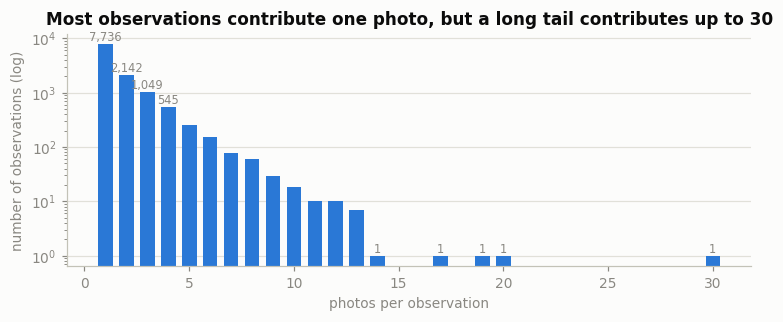

In [12]:
photos_per_obs = df["observation_id"].value_counts()
print(photos_per_obs.describe().round(2).to_string())
print(f"\nshare of observations with >1 photo : "
      f"{(photos_per_obs > 1).mean():.1%}")
print(f"share of ROWS in multi-photo observations : "
      f"{df['observation_id'].map(photos_per_obs).gt(1).mean():.1%}")

counts = photos_per_obs.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(counts.index, counts.values, color=CAT[0], width=0.7)
ax.set_yscale("log")
ax.set_xlabel("photos per observation")
ax.set_ylabel("number of observations (log)")
ax.set_title("Most observations contribute one photo, but a long tail contributes up to 30")
ax.grid(axis="x", visible=False)
for x, v in counts.items():
    if x <= 4 or v <= 2:
        ax.text(x, v * 1.15, f"{v:,}", ha="center", fontsize=7.5, color=MUTED)
plt.tight_layout(); plt.show()

**Finding — the leakage rule for this dataset.** ~36% of rows belong to an observation that
contributes more than one photo. A random row-level train/test split would put near-identical
frames of the same individual on both sides and produce an optimistic, meaningless accuracy.

> **Splits must be grouped by `observation_id`** (e.g. `sklearn.model_selection.StratifiedGroupKFold`
> with `groups=observation_id`). §9 shows a second, weaker grouping candidate: the photographer.

---
## 6. Taxonomic label audit

`taxon.name` is returned at whatever rank the community agreed on, so the label column silently
mixes ranks. A binomial (*Vanessa cardui*) is a species; a single word (*Chrysura*) is a genus; a
trinomial (*Cicindela campestris cyprensis*) is a subspecies. Treated naively these become three
separate "classes" that may in fact be nested inside one another.

In [13]:
df["n_words"] = df["taxon_name"].str.split().str.len()
rank_map = {1: "genus (or higher)", 2: "species", 3: "subspecies"}
df["rank_guess"] = df["n_words"].map(rank_map).fillna("other")

rank_tab = (df.groupby("rank_guess", observed=True)
              .agg(rows=("taxon_name", "size"), distinct_taxa=("taxon_name", "nunique"))
              .assign(row_pct=lambda d: (d["rows"] / len(df) * 100).round(2))
              .sort_values("rows", ascending=False))
display(rank_tab)

for r in ["genus (or higher)", "subspecies"]:
    print(f"\n--- {r} examples ---")
    print(df.loc[df["rank_guess"] == r, "taxon_name"].value_counts().head(5).to_string())

,rows,distinct_taxa,row_pct
rank_guess,,,
species,20630,1081,96.39
subspecies,718,56,3.35
genus (or higher),55,17,0.26



--- genus (or higher) examples ---
taxon_name
Chrysura         11
Sphaerophoria     9
Velia             6
Gyrinus           4
Paragus           4

--- subspecies examples ---
taxon_name
Cicindela campestris cyprensis            87
Carpocoris mediterraneus mediterraneus    77
Truxalis eximia cypria                    41
Regiscolia maculata bischoffi             36
Oryctes nasicornis kuntzeni               32


In [14]:
# Do any subspecies labels overlap a species label that also exists on its own?
species = set(df.loc[df["n_words"] == 2, "taxon_name"])
sub = df.loc[df["n_words"] == 3, "taxon_name"].unique()
nested = sorted({s for s in sub if " ".join(s.split()[:2]) in species})
print(f"subspecies whose parent species is ALSO a label: {len(nested)} of {len(sub)}")
pd.Series(nested[:15], name="nested label").to_frame()

subspecies whose parent species is ALSO a label: 32 of 56


,nested label
0,Acmaeodera flavolineata cypricola
1,Acmaeodera ottomana confluens
2,Acrida ungarica mediterranea
3,Apis mellifera cypria
4,Bombus terrestris dalmatinus
5,Carpocoris mediterraneus mediterraneus
6,Cheilomenes propinqua nilotica
7,Cheilomenes propinqua vicina
8,Chlorophorus varius damascenus
9,Chorthippus maritimus maritimus


In [15]:
# Same check one level up: genus-only labels that also appear as the genus of a species label.
genus_only = set(df.loc[df["n_words"] == 1, "taxon_name"])
genus_of_species = set(s.split()[0] for s in species)
overlap = sorted(genus_only & genus_of_species)
print(f"genus-only labels that also head a species label: {len(overlap)} of {len(genus_only)}")
print(overlap[:20])

genus-only labels that also head a species label: 7 of 17
['Chrysura', 'Eumenes', 'Eumerus', 'Lasius', 'Sphaerophoria', 'Syritta', 'Velia']


**Finding — the label column is not a clean target variable.** Ranks are mixed, and a large share
of the coarse labels are *ancestors* of finer labels in the same column. A model trained on the raw
strings is penalised for a correct-but-coarser answer.

**Recommended target.** Normalise to a **species-level label** by truncating trinomials to their
first two words, and route genus-only rows to a separate bucket (either dropped, or kept only when
the genus is not otherwise represented). This is applied in §12 as `label_species`.

In [16]:
df["label_species"] = df["taxon_name"].str.split().str[:2].str.join(" ")
df.loc[df["n_words"] == 1, "label_species"] = pd.NA   # genus-only: no species available

print(f"species-level labels        : {df['label_species'].nunique():,} "
      f"(raw taxon_name: {df['taxon_name'].nunique():,})")
print(f"rows with no species label  : {pct(df['label_species'].isna().sum(), len(df))}")

species-level labels        : 1,105 (raw taxon_name: 1,154)
rows with no species label  : 55 (0.3%)


---
## 7. Class distribution & imbalance

The classic failure mode of a scraped biodiversity dataset: a handful of charismatic, common
species dominate while the majority of classes have a handful of photos. The question is not "is it
imbalanced" (it is) but **how many classes survive a usable minimum-support threshold**.

In [17]:
vc = df["label_species"].value_counts()
print(vc.describe().round(2).to_string())
print(f"\nclasses with a single photo : {pct((vc == 1).sum(), len(vc))} of classes")
print(f"top-10 classes cover        : {vc.head(10).sum() / vc.sum():.1%} of rows")
print(f"top-50 classes cover        : {vc.head(50).sum() / vc.sum():.1%} of rows")
vc.head(15).to_frame("photos")

count    1105.00
mean       19.32
std        38.67
min         1.00
25%         2.00
50%         6.00
75%        18.00
max       409.00

classes with a single photo : 173 (15.7%) of classes
top-10 classes cover        : 14.3% of rows
top-50 classes cover        : 37.5% of rows


,photos
label_species,
Utetheisa pulchella,409
Vanessa cardui,362
Sphodromantis viridis,360
Coccinella septempunctata,308
Sympetrum fonscolombii,297
Papilio machaon,290
Apis mellifera,281
Palpita vitrealis,275
Dolycoris baccarum,238


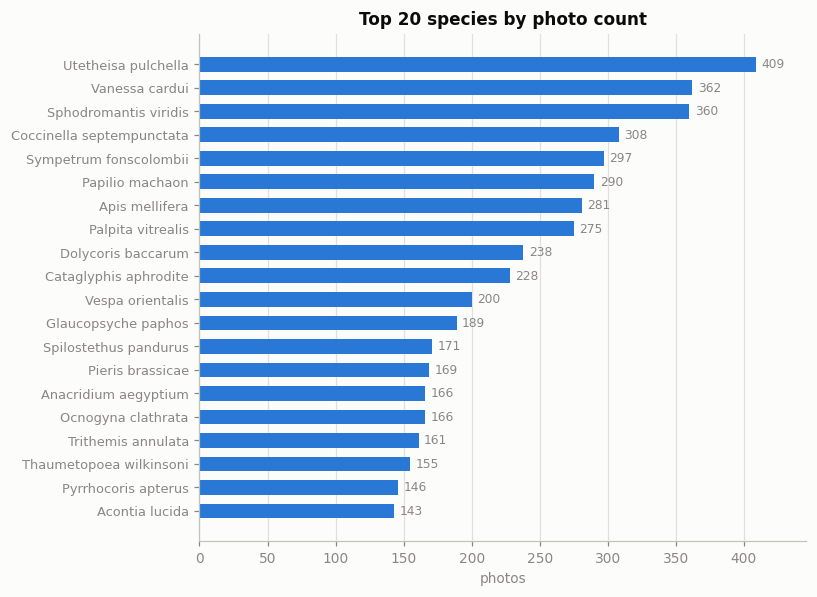

In [18]:
top = vc.head(20).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.barh(top.index, top.values, color=CAT[0], height=0.62)
for y, (name, v) in enumerate(top.items()):
    ax.text(v + 4, y, f"{v}", va="center", fontsize=8, color=MUTED)
ax.set_xlabel("photos")
ax.set_title("Top 20 species by photo count")
ax.set_xlim(0, top.max() * 1.09)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8.5)
plt.tight_layout(); plt.show()

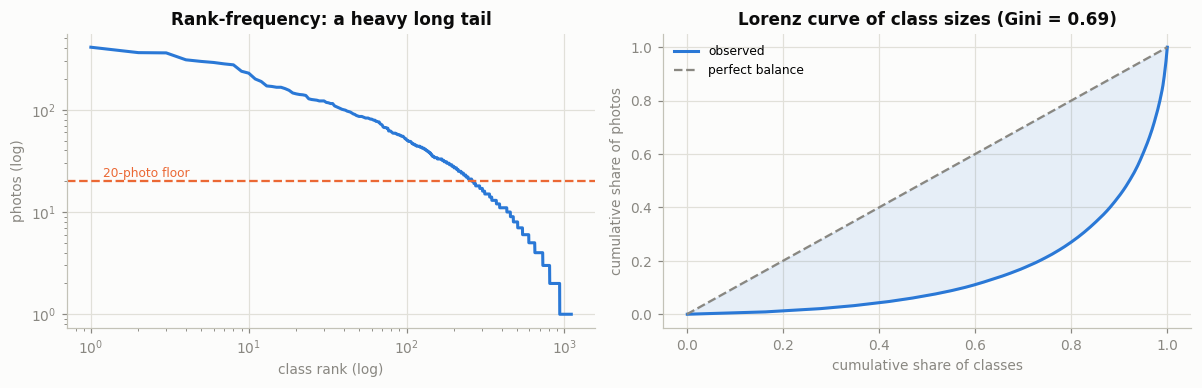

Gini coefficient of class sizes: 0.691  (0 = balanced, 1 = one class holds everything)


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

# (a) rank-frequency curve -- the long tail, on log-log
ax = axes[0]
ax.plot(np.arange(1, len(vc) + 1), vc.values, color=CAT[0], lw=2)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("class rank (log)"); ax.set_ylabel("photos (log)")
ax.set_title("Rank-frequency: a heavy long tail")
ax.axhline(20, color=CAT[1], lw=1.5, ls="--")
ax.text(1.2, 22, "20-photo floor", color=CAT[1], fontsize=8)

# (b) Lorenz curve -- concentration
ax = axes[1]
s = np.sort(vc.values)
cum = np.cumsum(s) / s.sum()
x = np.arange(1, len(s) + 1) / len(s)
gini = 1 - 2 * np.trapz(cum, x)
ax.plot(x, cum, color=CAT[0], lw=2, label="observed")
ax.plot([0, 1], [0, 1], color=MUTED, lw=1.5, ls="--", label="perfect balance")
ax.fill_between(x, cum, x, color=CAT[0], alpha=0.10)
ax.set_xlabel("cumulative share of classes"); ax.set_ylabel("cumulative share of photos")
ax.set_title(f"Lorenz curve of class sizes (Gini = {gini:.2f})")
ax.legend(loc="upper left", fontsize=8)

plt.tight_layout(); plt.show()
print(f"Gini coefficient of class sizes: {gini:.3f}  (0 = balanced, 1 = one class holds everything)")

,classes_kept,photos_kept,photos_kept_%,obs_kept
min_photos_per_class,,,,
1,1105,21348,100.0,12065
5,648,20370,95.4,11395
10,454,19101,89.5,10744
20,266,16568,77.6,9401
30,186,14641,68.6,8354
50,102,11478,53.8,6684
100,40,7092,33.2,4236


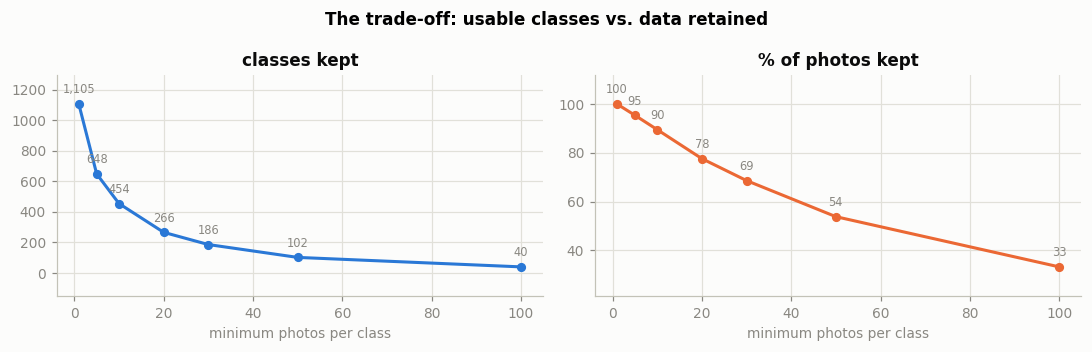

In [20]:
# How much data survives a minimum-photos-per-class rule?
rows = []
for k in [1, 5, 10, 20, 30, 50, 100]:
    keep = vc[vc >= k]
    rows.append({"min_photos_per_class": k,
                 "classes_kept": len(keep),
                 "photos_kept": int(keep.sum()),
                 "photos_kept_%": round(keep.sum() / vc.sum() * 100, 1),
                 "obs_kept": int(df[df["label_species"].isin(keep.index)]["observation_id"].nunique())})
thresh = pd.DataFrame(rows).set_index("min_photos_per_class")
display(thresh)

# Two different units -> two panels sharing an x axis, never a second y scale.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharex=True)
for ax, col, lab, c in [(axes[0], "classes_kept", "classes kept", CAT[0]),
                        (axes[1], "photos_kept_%", "% of photos kept", CAT[1])]:
    ax.plot(thresh.index, thresh[col], color=c, lw=2, marker="o", ms=5)
    for x, v in thresh[col].items():
        ax.annotate(f"{v:,.0f}", (x, v), textcoords="offset points", xytext=(0, 7),
                    ha="center", fontsize=7.5, color=MUTED)
    ax.set_xlabel("minimum photos per class"); ax.set_title(lab)
    ax.margins(y=0.18)
fig.suptitle("The trade-off: usable classes vs. data retained", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

**Finding.** Class sizes are extremely skewed (Gini ≈ 0.7): a median class has only a handful of
photos while the largest has ~400, and a large fraction of classes are singletons that cannot even
be placed in both a train and a test split.

**Recommendation.** Adopt a minimum-support threshold — the table above makes the cost explicit.
A **≥ 20 photos per species** rule keeps a few hundred classes and the clear majority of the
photos, which is the usual sweet spot for a first model. Everything below the threshold is either
dropped or folded into a genus-level / "other" bucket rather than being silently mixed in.

---
## 8. Licence audit

The retriever requested five open licences. This section verifies that only those appear, and
separates them by what they actually permit — because `-nc` (non-commercial) and `-sa`
(share-alike) constrain how a trained model may be published.

In [21]:
lic = df["license_code"].value_counts(dropna=False)
lic_tab = lic.to_frame("photos").assign(pct=lambda d: (d["photos"] / len(df) * 100).round(2))
lic_tab["commercial_use"] = [c in {"cc0", "cc-by", "cc-by-sa"} if pd.notna(c) else False
                             for c in lic_tab.index]
lic_tab["share_alike"] = [str(c).endswith("sa") for c in lic_tab.index]
display(lic_tab)

allowed = {"cc0", "cc-by", "cc-by-sa", "cc-by-nc", "cc-by-nc-sa"}
unexpected = set(lic.index.dropna()) - allowed
print(f"licences outside the requested set: {unexpected or 'none'}")
print(f"commercial-use-safe photos : {pct(int(lic_tab.loc[lic_tab['commercial_use'], 'photos'].sum()), len(df))}")

,photos,pct,commercial_use,share_alike
license_code,,,,
cc-by-nc,16852,78.74,False,False
cc-by,3879,18.12,True,False
cc0,364,1.70,True,False
cc-by-nc-sa,223,1.04,False,True
cc-by-sa,84,0.39,True,True
NaN,1,0.00,False,False


licences outside the requested set: none
commercial-use-safe photos : 4,327 (20.2%)


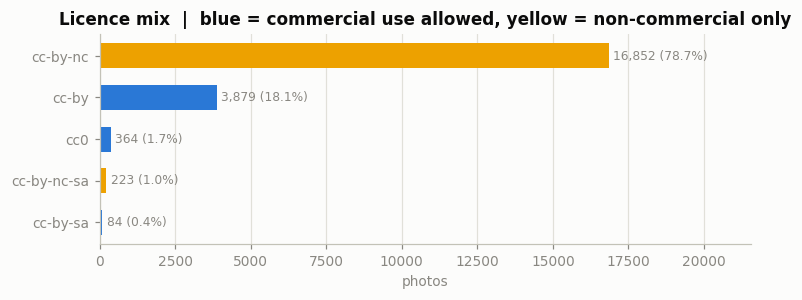

In [22]:
order = [c for c in ["cc-by-nc", "cc-by", "cc0", "cc-by-nc-sa", "cc-by-sa"] if c in lic.index]
vals = [lic[c] for c in order]
colors = [CAT[0] if c in {"cc0", "cc-by", "cc-by-sa"} else CAT[3] for c in order]

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(order[::-1], vals[::-1], color=colors[::-1], height=0.6)
for y, v in enumerate(vals[::-1]):
    ax.text(v + 150, y, f"{v:,} ({v/len(df):.1%})", va="center", fontsize=8, color=MUTED)
ax.set_xlim(0, max(vals) * 1.28)
ax.set_xlabel("photos")
ax.set_title("Licence mix  |  blue = commercial use allowed, yellow = non-commercial only")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Finding.** ~79% of the photos are **CC BY-NC**: free to use for research and teaching, but not in
a commercial product. Only ~20% (CC0 / CC BY / CC BY-SA) are commercial-safe. Two consequences:

* An academic model can use everything; a commercial one must be retrained on the ~20% subset,
  which would change the class distribution — so `license_code` should be carried through the
  pipeline, not dropped at load time.
* Attribution is contractually required for every code except CC0, so the `attribution` column is
  part of the deliverable, not just metadata.

---
## 9. Contributor audit

`attribution` is a formatted copyright line; the photographer's name can be parsed out of it.
Contributor concentration matters because one person's photos share a camera, a garden and a style
— a second source of correlation between rows.

In [23]:
def parse_photographer(s):
    if pd.isna(s):
        return None
    s = re.sub(r"^\(c\)\s*", "", s)                     # leading (c)
    s = re.split(r",\s*(?:some rights reserved|all rights reserved|no rights reserved)", s)[0]
    s = re.sub(r"\s*\(CC[^)]*\)\s*$", "", s)
    return s.strip() or None

df["photographer"] = df["attribution"].map(parse_photographer)
print(f"distinct photographers : {df['photographer'].nunique():,}")
print(f"unparsed attributions  : {df['photographer'].isna().sum():,}")
df["photographer"].value_counts().head(10).to_frame("photos")

distinct photographers : 789
unparsed attributions  : 0


,photos
photographer,
Reflectitur Photons,4693
Jakovos Demetriou,1592
Louis Aureglia,1227
tallmonkee,804
Marios Thoma,675
Konstantin Grebennikov,569
"Andy Goerdel - Texas Master Naturalist, Good Water Chapter",537
Martin Vašina,474
Chris Lamsdell,375


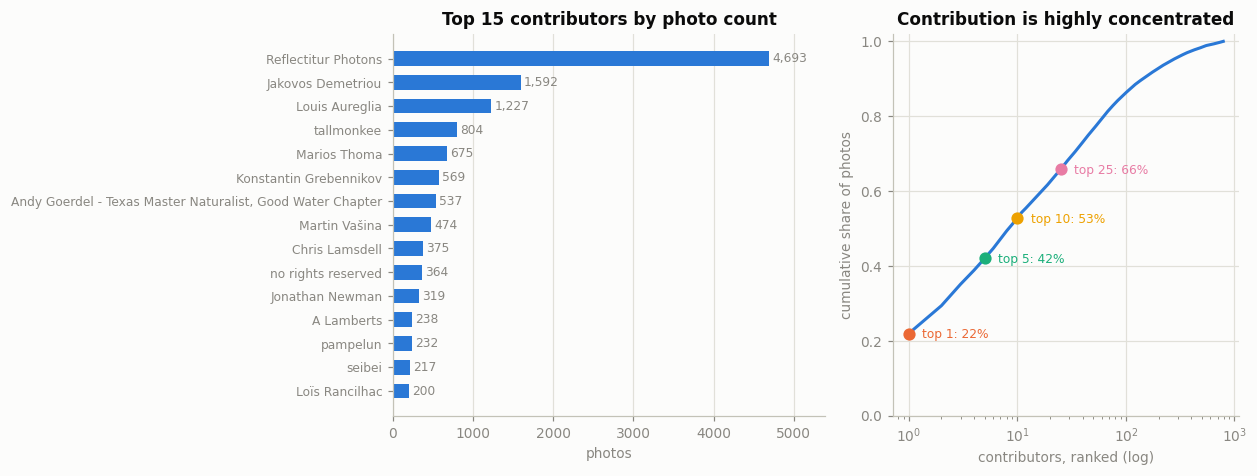

In [24]:
pv = df["photographer"].value_counts()
share = pv / pv.sum()
top = pv.head(15).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4),
                         gridspec_kw={"width_ratios": [1.25, 1]})

ax = axes[0]
ax.barh(top.index, top.values, color=CAT[0], height=0.62)
for y, v in enumerate(top.values):
    ax.text(v + 40, y, f"{v:,}", va="center", fontsize=8, color=MUTED)
ax.set_xlim(0, top.max() * 1.15)
ax.set_title("Top 15 contributors by photo count")
ax.set_xlabel("photos"); ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)

ax = axes[1]
cum = share.cumsum().reset_index(drop=True)
ax.plot(np.arange(1, len(cum) + 1), cum.values, color=CAT[0], lw=2)
for k, c in zip([1, 5, 10, 25], CAT[1:5]):
    ax.plot([k], [cum.iloc[k - 1]], marker="o", ms=7, color=c)
    ax.annotate(f"top {k}: {cum.iloc[k-1]:.0%}", (k, cum.iloc[k - 1]),
                textcoords="offset points", xytext=(9, -3), fontsize=8, color=c)
ax.set_xscale("log")
ax.set_xlabel("contributors, ranked (log)"); ax.set_ylabel("cumulative share of photos")
ax.set_ylim(0, 1.02)
ax.set_title("Contribution is highly concentrated")

plt.tight_layout(); plt.show()

In [25]:
# Does any single photographer own a whole class? That is the dangerous case.
by_class = (df.dropna(subset=["label_species"])
              .groupby("label_species")
              .agg(photos=("photographer", "size"),
                   photographers=("photographer", "nunique"),
                   top_share=("photographer", lambda s: s.value_counts(normalize=True).iloc[0])))
usable = by_class[by_class["photos"] >= 20]
print(f"classes with >= 20 photos                    : {len(usable):,}")
print(f"  ... of which one photographer owns >= 80%  : {pct((usable['top_share'] >= .8).sum(), len(usable))}")
print(f"  ... of which one photographer owns >= 50%  : {pct((usable['top_share'] >= .5).sum(), len(usable))}")
usable.sort_values("top_share", ascending=False).head(10)

classes with >= 20 photos                    : 266
  ... of which one photographer owns >= 80%  : 32 (12.0%)
  ... of which one photographer owns >= 50%  : 86 (32.3%)


,photos,photographers,top_share
label_species,,,
Aphaenogaster simonellii,31,1,1.000000
Psacasta tuberculata,32,1,1.000000
Nemognatha chrysomelina,24,1,1.000000
Camponotus baldaccii,44,1,1.000000
Aphaenogaster subterraneoides,25,1,1.000000
Achyra nudalis,82,2,0.987805
Phoracantha recurva,77,2,0.987013
Ventocoris achivus,49,2,0.979592
Aelia acuminata,46,3,0.956522


**Finding.** Contribution follows a steep power law — a handful of prolific naturalists account for
a large share of every photo in the file, and for a number of the usable classes a *single*
photographer supplies most or all of the images.

**Implication.** For those classes the model can learn the photographer's background and lighting
instead of the insect. Two mitigations, in order of strength: report a **photographer-disjoint
evaluation** alongside the standard one, and apply strong photometric augmentation. `observation_id`
remains the mandatory grouping key (§5); photographer is the diagnostic one.

---
## 10. Location audit

`place_guess` is free text typed by users, so the same place appears in several languages and
formats (*"Paphos, Cyprus"*, *"Paphos, CY"*, *"District de Limassol, Chypre"*). It is unusable as a
categorical feature until normalised, and even then it is coarse.

In [26]:
loc = df["location"].dropna()
print(f"distinct raw location strings : {loc.nunique():,} for {loc.shape[0]:,} rows")
loc.value_counts().head(15).to_frame("photos")

distinct raw location strings : 2,131 for 21,095 rows


,photos
location,
"Nicosia, Cyprus",3373
"Pissouri, Cyprus",1065
"Melanos, Chloraka, Cyprus",650
"Paphos, CY",531
"Paphos, Cyprus",466
"District de Limassol, Chypre",275
"Álassa, Chypre",254
"Larnaca, Cyprus",243
"Larnaca, CY",234


In [27]:
# Evidence of the formatting problem: how the country component alone is written.
country = loc.str.split(",").str[-1].str.strip().str.lower()
country.value_counts().head(12).to_frame("photos")

,photos
location,
cyprus,11374
cy,3201
chypre,2010
zypern,1121
кипр,702
kypr,638
cypr,387
cipro,289
кіпр,147


,photos,pct
district,,
other / unmatched,10060,47.0
nicosia,4662,21.8
paphos,3279,15.3
larnaca,1241,5.8
limassol,1007,4.7
famagusta,846,4.0
unknown,308,1.4


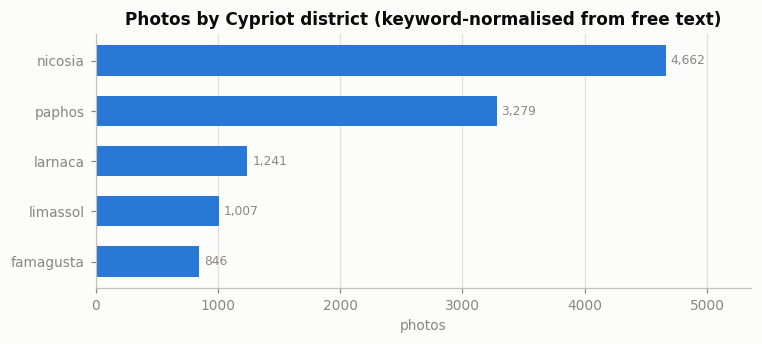

strings that matched no district: 10,060 (47.0%)


In [28]:
# Light normalisation: map free text onto the six Cypriot districts by keyword.
DISTRICTS = {
    "nicosia":  ["nicosia", "lefkosia", "lefkosa", "λευκωσία", "nikosia", "nicosie"],
    "limassol": ["limassol", "lemesos", "λεμεσός", "limasol"],
    "paphos":   ["paphos", "pafos", "πάφος", "baf"],
    "larnaca":  ["larnaca", "larnaka", "λάρνακα"],
    "famagusta":["famagusta", "ammochostos", "gazimagusa", "αμμόχωστος", "protaras", "ayia napa", "agia napa"],
    "kyrenia":  ["kyrenia", "girne", "keryneia", "κερύνεια"],
}

def to_district(s):
    if pd.isna(s):
        return "unknown"
    t = s.lower()
    for d, keys in DISTRICTS.items():
        if any(k in t for k in keys):
            return d
    return "other / unmatched"

df["district"] = df["location"].map(to_district)
dist = df["district"].value_counts()
display(dist.to_frame("photos").assign(pct=lambda d: (d["photos"] / len(df) * 100).round(1)))

named = dist.drop(["unknown", "other / unmatched"], errors="ignore").sort_values()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(named.index, named.values, color=CAT[0], height=0.6)
for y, v in enumerate(named.values):
    ax.text(v + 40, y, f"{v:,}", va="center", fontsize=8, color=MUTED)
ax.set_xlim(0, named.max() * 1.15)
ax.set_xlabel("photos"); ax.grid(axis="y", visible=False)
ax.set_title("Photos by Cypriot district (keyword-normalised from free text)")
plt.tight_layout(); plt.show()
print(f"strings that matched no district: {pct(int(dist.get('other / unmatched', 0)), len(df))}")

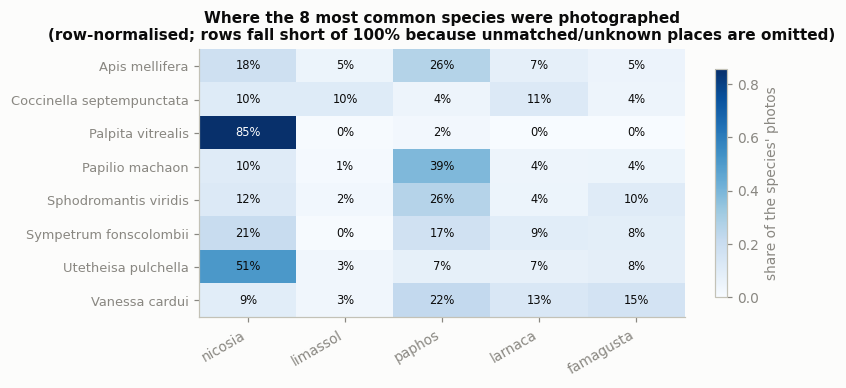

In [29]:
# Does geography interact with the label? (Sampling bias check on the biggest classes.)
top_species = vc.head(8).index
cross = pd.crosstab(df[df["label_species"].isin(top_species)]["label_species"],
                    df[df["label_species"].isin(top_species)]["district"], normalize="index")
cols = [c for c in ["nicosia", "limassol", "paphos", "larnaca", "famagusta", "kyrenia"] if c in cross]
cross = cross[cols]

fig, ax = plt.subplots(figsize=(7.5, 3.6))
im = ax.imshow(cross.values, cmap=SEQ, vmin=0, vmax=cross.values.max(), aspect="auto")
ax.set_xticks(range(len(cross.columns)), cross.columns, rotation=30, ha="right")
ax.set_yticks(range(len(cross.index)), cross.index, fontsize=8.5)
for i in range(cross.shape[0]):
    for j in range(cross.shape[1]):
        v = cross.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7.5,
                color="white" if v > cross.values.max() * 0.6 else INK)
ax.set_title("Where the 8 most common species were photographed\n"
             "(row-normalised; rows fall short of 100% because unmatched/unknown places are omitted)",
             fontsize=10)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.85, label="share of the species' photos")
plt.tight_layout(); plt.show()

**Finding.** Location is ~1.4% missing and highly redundant (2,131 distinct strings for a small
island, across at least three languages and two country codes). After normalisation the sampling is
clearly uneven — a few districts, and within them a few localities, dominate. The northern
districts are barely represented.

**Implication.** Location is fine as an *audit* dimension but should not be fed to the model as a
feature: it would let the classifier shortcut species identity via geography, and it generalises
badly to any new area.

---
## 11. Photo URL audit

The images are the actual model input, so the URLs deserve the same scrutiny as the labels: which
host serves them, which size variant was stored, and whether they still resolve.

In [30]:
df["host"] = df["photo_url"].str.extract(r"https?://([^/]+)/")
df["size_variant"] = df["photo_url"].str.extract(r"/([a-z]+)\.(?:jpe?g|png)", flags=re.I)
df["extension"] = df["photo_url"].str.extract(r"\.([a-z0-9]+)$", flags=re.I)[0].str.lower()

display(df["host"].value_counts().to_frame("photos"))
display(df["size_variant"].value_counts(dropna=False).to_frame("photos"))
display(df["extension"].value_counts(dropna=False).to_frame("photos"))

,photos
host,
inaturalist-open-data.s3.amazonaws.com,21402
static.inaturalist.org,1


,photos
size_variant,
square,21400
NaN,3


,photos
extension,
jpg,11644
jpeg,9734
png,22
gif,3


**Finding — the most consequential one in this audit.** Every stored URL is the `square` variant,
which iNaturalist serves as a **75 x 75 px centre-cropped thumbnail**. That is far below the input
resolution of any modern image classifier (224 x 224 and up) and the centre crop may not even
contain the insect.

The fix is free: the iNaturalist photo path is size-templated, so `square` can be swapped for
`medium` (~500 px) or `original` on the same URL. This should be done **before** any images are
downloaded.

In [31]:
def to_size(url, size="medium"):
    return re.sub(r"/(square|small|medium|large|original)\.", f"/{size}.", url)

df["photo_url_medium"] = df["photo_url"].map(lambda u: to_size(u, "medium"))
df[["photo_url", "photo_url_medium"]].head(3)

,photo_url,photo_url_medium
0,https://inaturalist-open-data.s3.amazonaws.com/photos/709822987/square.jpg,https://inaturalist-open-data.s3.amazonaws.com/photos/709822987/medium.jpg
1,https://inaturalist-open-data.s3.amazonaws.com/photos/709822622/square.jpg,https://inaturalist-open-data.s3.amazonaws.com/photos/709822622/medium.jpg
2,https://inaturalist-open-data.s3.amazonaws.com/photos/709822553/square.jpg,https://inaturalist-open-data.s3.amazonaws.com/photos/709822553/medium.jpg


In [32]:
# Availability spot-check on a random sample (needs network; skipped gracefully if offline).
import random
try:
    import requests
    sample = df["photo_url_medium"].drop_duplicates().sample(30, random_state=0)
    codes = []
    for u in sample:
        try:
            codes.append(requests.head(u, timeout=10, allow_redirects=True).status_code)
        except Exception as e:
            codes.append(type(e).__name__)
    res = pd.Series(codes).value_counts()
    display(res.to_frame("responses"))
    ok = res.get(200, 0)
    print(f"{ok}/{len(sample)} sampled images resolve ({ok/len(sample):.0%}). "
          "Extrapolate with care -- run the full check before downloading.")
except Exception as e:
    print(f"skipped live URL check: {e}")

,responses
200,30


30/30 sampled images resolve (100%). Extrapolate with care -- run the full check before downloading.


---
## 12. Data-quality scorecard & cleaned export

Every rule below traces back to a numbered finding, so the cleaning step is auditable rather than
folklore.

In [33]:
scorecard = pd.DataFrame([
    ("Completeness", "taxon_name / photo_url complete",        "PASS", "0 nulls (S4)"),
    ("Completeness", "location present",                        "WARN", f"{df['location'].isna().mean():.1%} null (S4)"),
    ("Validity",     "licence inside requested open set",       "WARN", "1 all-rights-reserved row (S4/S8)"),
    ("Uniqueness",   "no exact duplicate rows",                 "PASS", "0 rows (S5)"),
    ("Uniqueness",   "no repeated image files",                 "WARN", f"{df['photo_url'].duplicated().sum()} rows (S5)"),
    ("Independence", "one row = one independent example",       "FAIL", "rows nest in observations (S5)"),
    ("Consistency",  "label column at a single rank",           "FAIL", "genus/species/subspecies mixed (S6)"),
    ("Balance",      "classes usably sized",                    "FAIL", f"Gini {gini:.2f}, many singletons (S7)"),
    ("Representativeness", "contributors diverse per class",    "WARN", "single-photographer classes (S9)"),
    ("Fitness",      "image resolution adequate",               "FAIL", "all URLs are 75px squares (S11)"),
], columns=["dimension", "check", "status", "evidence"])
scorecard.style.hide(axis="index") if hasattr(scorecard, "style") else scorecard

dimension,check,status,evidence
Completeness,taxon_name / photo_url complete,PASS,0 nulls (S4)
Completeness,location present,WARN,1.4% null (S4)
Validity,licence inside requested open set,WARN,1 all-rights-reserved row (S4/S8)
Uniqueness,no exact duplicate rows,PASS,0 rows (S5)
Uniqueness,no repeated image files,WARN,6 rows (S5)
Independence,one row = one independent example,FAIL,rows nest in observations (S5)
Consistency,label column at a single rank,FAIL,genus/species/subspecies mixed (S6)
Balance,classes usably sized,FAIL,"Gini 0.69, many singletons (S7)"
Representativeness,contributors diverse per class,WARN,single-photographer classes (S9)
Fitness,image resolution adequate,FAIL,all URLs are 75px squares (S11)


In [34]:
clean = df.copy()
n0 = len(clean)
log = []

def step(name, frame):
    global clean
    log.append({"step": name, "rows_after": len(frame), "rows_removed": len(clean) - len(frame)})
    clean = frame

step("drop non-open licence (S4/S8)",  clean[clean["license_code"].notna()])
step("drop repeated image files (S5)", clean.drop_duplicates(subset="photo_url", keep="first"))
step("drop genus-only labels (S6)",    clean[clean["label_species"].notna()])

MIN_PHOTOS = 20
keep = clean["label_species"].value_counts()
keep = keep[keep >= MIN_PHOTOS].index
step(f"drop classes with < {MIN_PHOTOS} photos (S7)", clean[clean["label_species"].isin(keep)])

display(pd.DataFrame(log).set_index("step"))
print(f"\n{len(clean):,} rows retained of {n0:,} ({len(clean)/n0:.1%})")
print(f"{clean['label_species'].nunique():,} classes | "
      f"{clean['observation_id'].nunique():,} observations | "
      f"{clean['photographer'].nunique():,} photographers")
print(f"photos per class: min {clean['label_species'].value_counts().min()}, "
      f"median {clean['label_species'].value_counts().median():.0f}, "
      f"max {clean['label_species'].value_counts().max()}")

,rows_after,rows_removed
step,,
drop non-open licence (S4/S8),21402,1
drop repeated image files (S5),21396,6
drop genus-only labels (S6),21341,55
drop classes with < 20 photos (S7),16561,4780



16,561 rows retained of 21,403 (77.4%)
266 classes | 9,401 observations | 741 photographers
photos per class: min 20, median 40, max 409


In [35]:
OUT_COLS = ["observation_id", "label_species", "taxon_name", "photo_url", "photo_url_medium",
            "license_code", "attribution", "photographer", "location", "district"]
out = clean[OUT_COLS].reset_index(drop=True)
out_path = DATA.parent / "insects_clean.csv"
out.to_csv(out_path, index=False)
print(f"wrote {len(out):,} rows -> {out_path}")
out.head()

wrote 16,561 rows -> /Users/nicolasdilegardia/Desktop/insects/Data/insects_clean.csv


,observation_id,label_species,taxon_name,photo_url,photo_url_medium,license_code,attribution,photographer,location,district
0,387625264,Utetheisa pulchella,Utetheisa pulchella,https://inaturalist-open-data.s3.amazonaws.com/photos/709822987/square.jpg,https://inaturalist-open-data.s3.amazonaws.com/photos/709822987/medium.jpg,cc-by-nc,"(c) Reflectitur Photons, some rights reserved (CC BY-NC)",Reflectitur Photons,"Nicosia, Cyprus",nicosia
1,387625095,Macroscytus brunneus,Macroscytus brunneus,https://inaturalist-open-data.s3.amazonaws.com/photos/709822622/square.jpg,https://inaturalist-open-data.s3.amazonaws.com/photos/709822622/medium.jpg,cc-by-nc,"(c) Reflectitur Photons, some rights reserved (CC BY-NC)",Reflectitur Photons,"Nicosia, Cyprus",nicosia
2,387625063,Vespa orientalis,Vespa orientalis,https://inaturalist-open-data.s3.amazonaws.com/photos/709822553/square.jpg,https://inaturalist-open-data.s3.amazonaws.com/photos/709822553/medium.jpg,cc-by-nc,"(c) Reflectitur Photons, some rights reserved (CC BY-NC)",Reflectitur Photons,"Nicosia, Cyprus",nicosia
3,387618636,Phoracantha recurva,Phoracantha recurva,https://inaturalist-open-data.s3.amazonaws.com/photos/709810271/square.jpg,https://inaturalist-open-data.s3.amazonaws.com/photos/709810271/medium.jpg,cc-by-nc,"(c) Reflectitur Photons, some rights reserved (CC BY-NC)",Reflectitur Photons,"Nicosia, Cyprus",nicosia
4,387618636,Phoracantha recurva,Phoracantha recurva,https://inaturalist-open-data.s3.amazonaws.com/photos/709810366/square.jpg,https://inaturalist-open-data.s3.amazonaws.com/photos/709810366/medium.jpg,cc-by-nc,"(c) Reflectitur Photons, some rights reserved (CC BY-NC)",Reflectitur Photons,"Nicosia, Cyprus",nicosia


In [36]:
# Sanity check that the cleaned frame can actually be split by group without losing classes.
from collections import Counter
grp = out.groupby("label_species")["observation_id"].nunique()
print(f"classes with only ONE observation (cannot be group-split): "
      f"{pct((grp == 1).sum(), len(grp))}")
print(f"classes with >= 5 observations: {pct((grp >= 5).sum(), len(grp))}")
grp.describe().round(1).to_frame("observations per class")

classes with only ONE observation (cannot be group-split): 0 (0.0%)
classes with >= 5 observations: 258 (97.0%)


,observations per class
count,266.0
mean,35.3
std,39.1
min,2.0
25%,14.0
50%,22.0
75%,41.8
max,279.0


---
## 13. Findings & recommendations

### What the data is
21,403 photo records covering ~12,100 research-grade insect observations from Cyprus, 1,154 raw
taxon labels, 791 contributors, five Creative Commons licences. Labels and image URLs are 100%
complete and the file is structurally sound — no parse errors, no type violations, no exact
duplicate rows.

### Blocking issues (must be fixed before modelling)

| # | Issue | Section | Fix |
|---|-------|---------|-----|
| 1 | Rows are **not independent** — up to 30 photos per observation, ~36% of rows affected | §5 | Group all splits by `observation_id` (`StratifiedGroupKFold`) |
| 2 | Labels **mix taxonomic ranks**, with coarse labels nested inside finer ones | §6 | Normalise to `label_species`; bucket genus-only rows |
| 3 | **Severe class imbalance** (Gini ≈ 0.7, many singleton classes) | §7 | Minimum-support threshold (≥ 20 photos), class weights / resampling |
| 4 | Stored URLs are **75 px thumbnails** | §11 | Rewrite `square` → `medium`/`original` before downloading |

### Cautions (do not block, but shape the conclusions)

* **Licence**: ~79% non-commercial. Fine for research; a commercial model must be retrained on the
  ~20% commercial-safe subset. Attribution is required for all but CC0. (§8)
* **Contributor concentration**: a few photographers dominate, and some classes come almost entirely
  from one person — report a photographer-disjoint score as a robustness check. (§9)
* **Geographic skew**: sampling is concentrated in a few districts; `location` is free text in three
  languages. Use it for auditing, not as a model feature. (§10)
* **6 repeated image files** and **1 all-rights-reserved photo** removed in cleaning. (§5, §4)

### Deliverable
`Data/insects_clean.csv` — deduplicated, licence-clean, species-labelled, ≥ 20 photos per class,
with a `photo_url_medium` column ready for download and a `district` column for stratified auditing.

### Suggested next steps
1. Download the `medium` images with the grouped split materialised up front, so no image is ever
   seen by both train and test.
2. Establish a baseline (fine-tuned ImageNet backbone), reporting macro-F1 rather than accuracy
   given the imbalance, plus the photographer-disjoint score.
3. Optionally enrich via the iNaturalist API with the fields the retriever did not keep —
   `observed_on`, latitude/longitude, and the full taxonomic hierarchy — which would enable
   seasonal analysis, proper geospatial stratification, and hierarchical (family → genus → species)
   classification.